In [20]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os
import urllib.request

# Display settings
pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

Download the dataset

In [21]:
# Download Telco Customer Churn dataset

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

os.makedirs("data", exist_ok=True)

file_path = "data/Telco-Customer-Churn.csv"

urllib.request.urlretrieve(url, file_path)

print("Dataset downloaded successfully!")
print("File size:", os.path.getsize(file_path), "bytes")

Dataset downloaded successfully!
File size: 970457 bytes


Load and inspect the dataset

In [22]:
# Load dataset
df = pd.read_csv("data/Telco-Customer-Churn.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null

Data cleaning

In [23]:

# 1. Create a copy of the dataset
df_clean = df.copy()

# 2. Remove customerID because it does not help predict churn
df_clean.drop("customerID", axis=1, inplace=True)

# 3. Convert TotalCharges to numeric
# Invalid or empty values will become NaN
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"], errors="coerce"
)

# 4. Check missing values
print("Missing values after conversion:")
print(df_clean.isnull().sum())

# 5. Remove rows with missing TotalCharges
df_clean.dropna(subset=["TotalCharges"], inplace=True)

# 6. Check duplicates
print("\nNumber of duplicate rows:", df_clean.duplicated().sum())

print("\nCleaned dataset shape:", df_clean.shape)

display(df_clean.head())


C:\Users\U\AppData\Local\Temp\ipykernel_5668\3308517926.py:5: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_clean.drop("customerID", axis=1, inplace=True)
C:\Users\U\AppData\Local\Temp\ipykernel_5668\3308517926.py:18: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_clean.dropna(subset=["TotalCharges"], inplace=True)


Missing values after conversion:
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Number of duplicate rows: 22

Cleaned dataset shape: (7032, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Exploratory Data Analysis

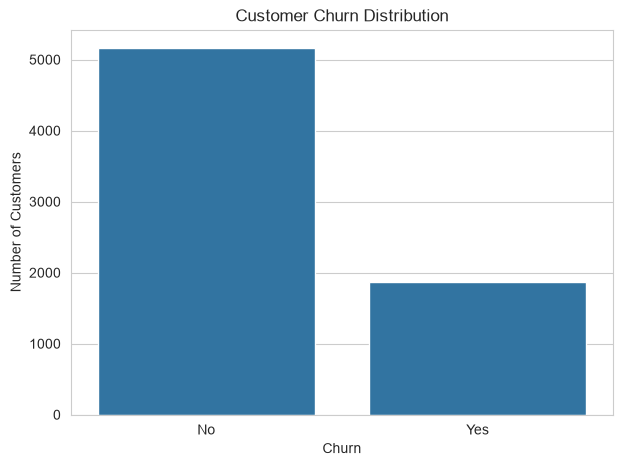

Churn percentages:
Churn
No     73.421502
Yes    26.578498
Name: proportion, dtype: float64


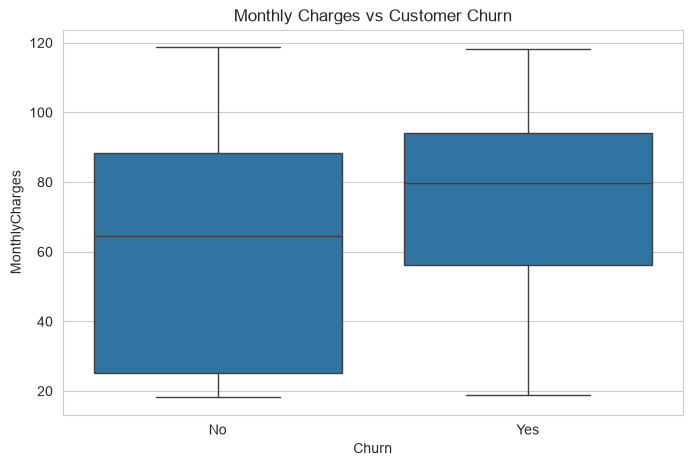

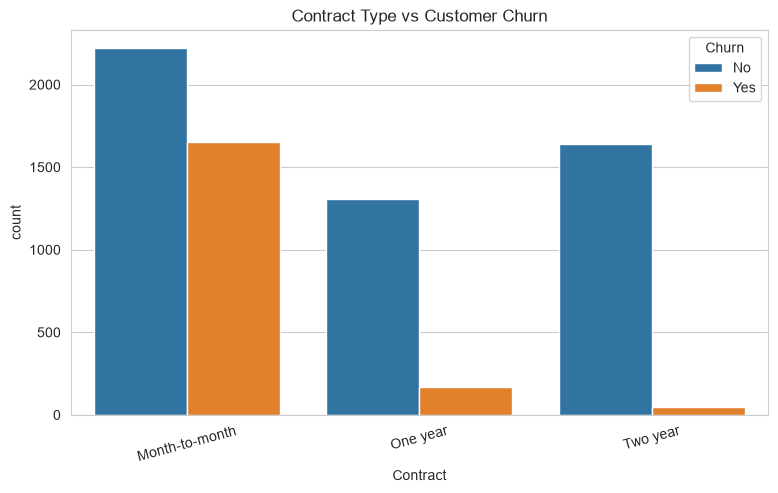

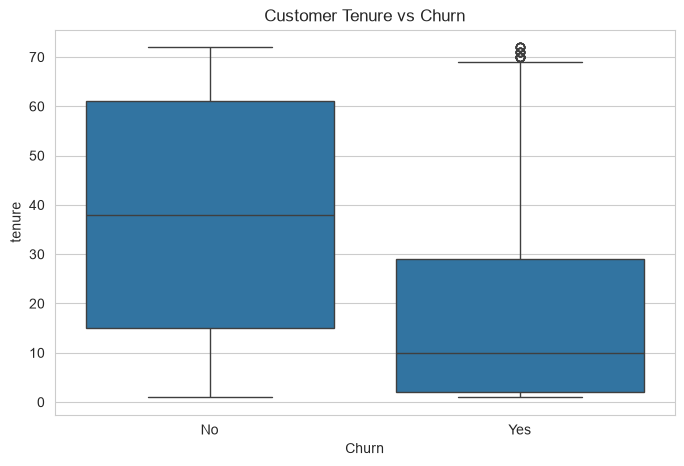

In [24]:

# 1. Churn distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

# 2. Churn percentages
print("Churn percentages:")
print(df_clean["Churn"].value_counts(normalize=True) * 100)

# 3. Monthly charges by churn
plt.figure(figsize=(8, 5))

sns.boxplot(data=df_clean, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges vs Customer Churn")
plt.show()

# 4. Contract type vs churn
plt.figure(figsize=(9, 5))

sns.countplot(data=df_clean, x="Contract", hue="Churn")

plt.title("Contract Type vs Customer Churn")
plt.xticks(rotation=15)
plt.show()

# 5. Tenure vs churn
plt.figure(figsize=(8, 5))

sns.boxplot(data=df_clean, x="Churn", y="tenure")

plt.title("Customer Tenure vs Churn")
plt.show()


Understand class imbalance

Customer Churn Classes:
Churn
No     5163
Yes    1869
Name: count, dtype: int64

Class percentages:
Churn
No     73.42
Yes    26.58
Name: count, dtype: float64


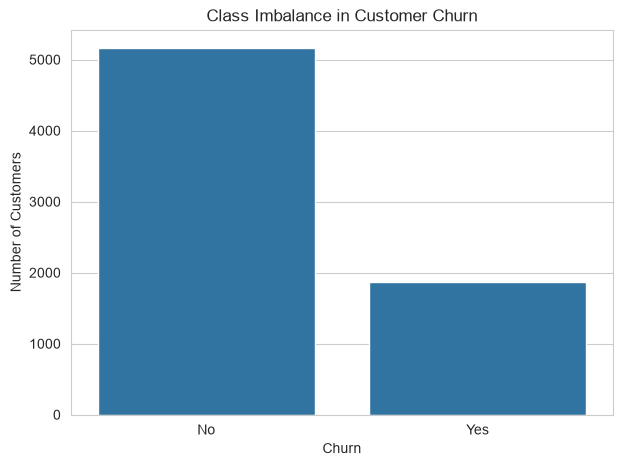

In [25]:

# Calculate class distribution
churn_counts = df_clean["Churn"].value_counts()

print("Customer Churn Classes:")
print(churn_counts)

print("\nClass percentages:")
print((churn_counts / len(df_clean) * 100).round(2))

# Visualize class imbalance
plt.figure(figsize=(7, 5))

sns.barplot(
    x=churn_counts.index,
    y=churn_counts.values
)

plt.title("Class Imbalance in Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()


Feature preparation and train/test split

In [26]:

# Separate features (X) and target (y)

X = df_clean.drop("Churn", axis=1)
y = df_clean["Churn"].map({"No": 0, "Yes": 1})

# Convert categorical features into numerical features
X = pd.get_dummies(X, drop_first=True, dtype=int)

# Split data into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset information
print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

print("\nNumber of features:", X_train.shape[1])


Training set shape: (5625, 30)
Testing set shape: (1407, 30)

Training target distribution:
Churn
0    4130
1    1495
Name: count, dtype: int64

Testing target distribution:
Churn
0    1033
1     374
Name: count, dtype: int64

Number of features: 30


Handle class imbalance with SMOTE

In [27]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [28]:

from imblearn.over_sampling import SMOTE

# Check class distribution before SMOTE
print("Before SMOTE:")
print(y_train.value_counts())

# Apply SMOTE only to training data
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

# Check class distribution after SMOTE
print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

print("\nNew training shape:", X_train_smote.shape)


Before SMOTE:
Churn
0    4130
1    1495
Name: count, dtype: int64

After SMOTE:
Churn
0    4130
1    4130
Name: count, dtype: int64

New training shape: (8260, 30)


Train the Random Forest model

In [29]:

from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    max_depth=15
)

# Train the model using SMOTE data
rf_model.fit(X_train_smote, y_train_smote)

# Make predictions
rf_predictions = rf_model.predict(X_test)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


Install and train XGBoost

In [30]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 451.8 kB/s eta 0:01:48
   ---------------------------------------- 0.5/48.9 MB 451.8 kB/s eta 0:01:48
    --------------------------------------- 0.8/48.9 MB 513.8 kB/s eta 0:01:34
    --------------------------------------- 0.8/48.9 MB 513.8 kB/s eta 0:01:34
    --------------------------------------- 1.0/48.9 MB 540.3 kB/s eta 0:01:29
    --------------------------------------- 1.0/48.9 MB 540.3 kB/s eta 0:01:29
   - -------------------------------------- 1.3/48.9 MB 537.4 kB/s eta 0:01:29
   - -------------------------------------- 1.3/48.9 MB 537.4 kB/s eta 0:01:29
   - -------------


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [31]:

from xgboost import XGBClassifier

# Create XGBoost model
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

# Train the model
xgb_model.fit(X_train_smote, y_train_smote)

# Make predictions
xgb_predictions = xgb_model.predict(X_test)

print("XGBoost model trained successfully!")


XGBoost model trained successfully!


Evaluate both models

In [32]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Function to evaluate a model
def evaluate_model(y_true, predictions, model_name):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions),
        "Recall": recall_score(y_true, predictions),
        "F1-Score": f1_score(y_true, predictions)
    }

# Compare models
results = []

results.append(
    evaluate_model(y_test, rf_predictions, "Random Forest")
)

results.append(
    evaluate_model(y_test, xgb_predictions, "XGBoost")
)

results_df = pd.DataFrame(results)

print("MODEL COMPARISON")
display(results_df.round(4))


MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.7733,0.5624,0.6631,0.6086
1,XGBoost,0.7676,0.5548,0.6364,0.5928


Confusion matrices and classification reports

RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

    No Churn       0.87      0.81      0.84      1033
       Churn       0.56      0.66      0.61       374

    accuracy                           0.77      1407
   macro avg       0.72      0.74      0.72      1407
weighted avg       0.79      0.77      0.78      1407


XGBOOST CLASSIFICATION REPORT
              precision    recall  f1-score   support

    No Churn       0.86      0.82      0.84      1033
       Churn       0.55      0.64      0.59       374

    accuracy                           0.77      1407
   macro avg       0.71      0.73      0.72      1407
weighted avg       0.78      0.77      0.77      1407



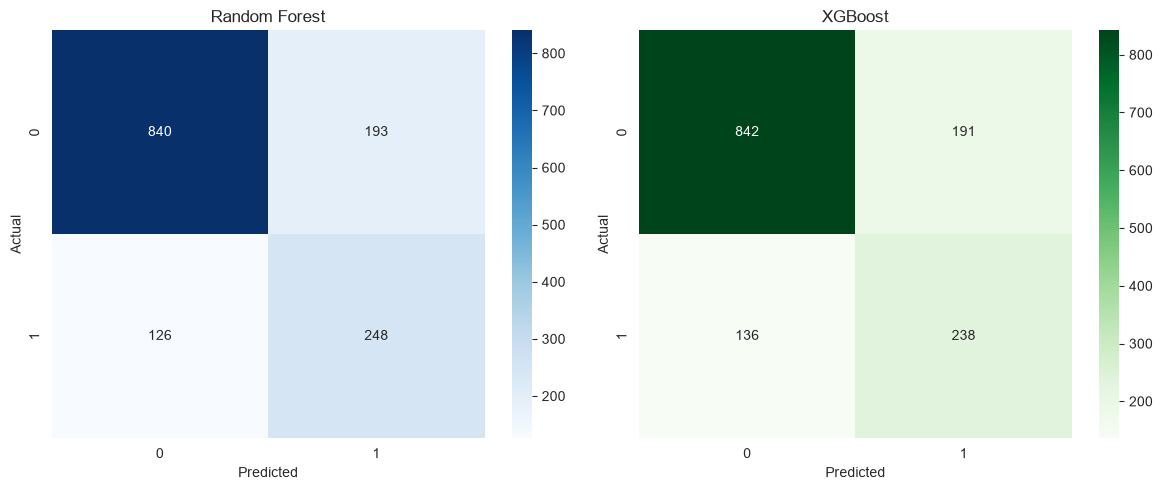

In [33]:

# Random Forest evaluation
print("RANDOM FOREST CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    rf_predictions,
    target_names=["No Churn", "Churn"]
))

# XGBoost evaluation
print("\nXGBOOST CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    xgb_predictions,
    target_names=["No Churn", "Churn"]
))

# Visualize confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    confusion_matrix(y_test, rf_predictions),
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Random Forest")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    confusion_matrix(y_test, xgb_predictions),
    annot=True,
    fmt="d",
    cmap="Greens",
    ax=axes[1]
)
axes[1].set_title("XGBoost")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()


Feature importance

In [ ]:

# Get Random Forest feature importance

importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("TOP 15 FEATURES INFLUENCING CUSTOMER CHURN")
display(importance.head(15))

# Visualize top 15 features
plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Customer Churn Features")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()
